# Time Series Forecasting models

# AR model

**we already check here that our data is non stationary and we have to convert it into stationary**

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf

In [3]:
# making data stationary before model fitting
stock_data=yf.download("AAPL",start="2023-01-01")

apple_price_stationary=stock_data["Close"].diff().dropna()

# Split the data into training and testing
train_data,test_data=apple_price_stationary[:-30],apple_price_stationary[-30:],

[*********************100%***********************]  1 of 1 completed


In [4]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_squared_error
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')


# Fit the Auto regressive model to the training data
model=AutoReg(train_data,lags=30)
model_fit=model.fit()

# make predicitions on the testing data
predictions=model_fit.predict(
    start=len(train_reset),
    end=len(train_reset)+len(test_data)-1,
    dynamic=False)


# Plot the actual v/s predicted values
plt.figure(figsize=(10,4))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",linestyle="--",label="Predicted Prices")
plt.title("Actual Price v/s Predicted values")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

# evaluating
rmse=round(np.sqrt(mean_squared_error(test_data,predictions)),2)
print("RMSE:",rmse)

NameError: name 'train_reset' is not defined

In [5]:
print(type(train_data.index))
print(train_data.index.freq)   # None means that's the problem

<class 'pandas.DatetimeIndex'>
None


In [6]:
# baselines
rmse_mean = np.sqrt(mean_squared_error(test_data, np.full(len(test_data), train_data.values.mean())))
rmse_zero = np.sqrt(mean_squared_error(test_data, np.zeros(len(test_data))))

print("AR(30) RMSE   :", rmse)
print("Mean baseline :", round(rmse_mean, 2))
print("Zero baseline :", round(rmse_zero, 2))
print("Test std      :", round(test_data.values.std(), 2))

NameError: name 'rmse' is not defined

In [7]:
len(train_data)

923

In [8]:
len(test_data)

30

# Moving average (MA) Model

<Day> Ticker
AAPL    422
dtype: int64


ValueError: Input contains NaN.

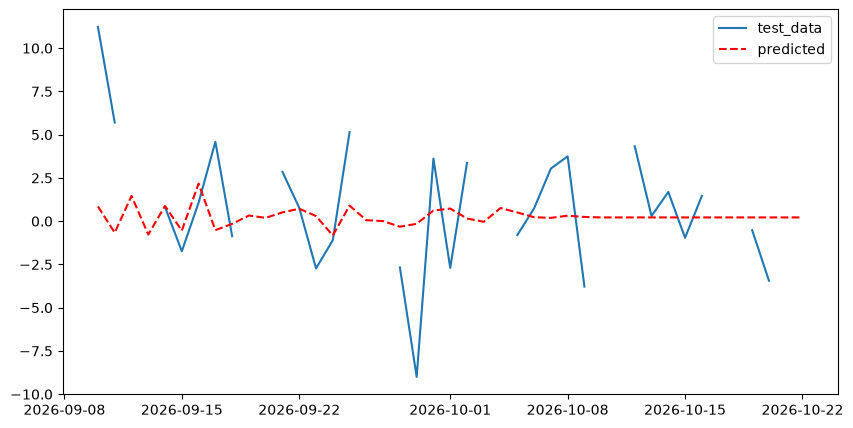

In [9]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

# make sure the index is date time with frequency
train_data=train_data.asfreq("D")
test_data=test_data.asfreq("D")
print(train_data.index.freq,train_data.isnull().sum())   # check no Nan were introduced

# Filling the moving average (MA ) model to the training data
model=ARIMA(train_data,order=(0,0,30))
model_fit=model.fit()

# make predicitons on the test data
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)

# Plot actual v/s the predicted data
plt.figure(figsize=(10,5))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",linestyle="--",label="predicted")
plt.legend()
plt.plot

# evaluating model using the RMSE model
rmse=round(np.sqrt(mean_squared_error(test_data,predictions)),2)
print("RMSE:",rmse)

# ARMA model

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Fit the moving average model
model=ARIMA(train_data,order=(7,0,7))
model_fit=model.fit()

# make predicitons on the test data
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)

# PLot the actual v/s the predicted
plt.figure(figsize=(10,5))
plt.plot(test_data.index,test_data,label="test_data")
plt.plot(test_data.index,predictions,color="red",label="Predicted Prices")
plt.title("AAPL actual v/s predicted price")
plt.xlabel("date")
plt.ylabel("Close Price")



plt.legend()
plt.show()

# ARIMA model

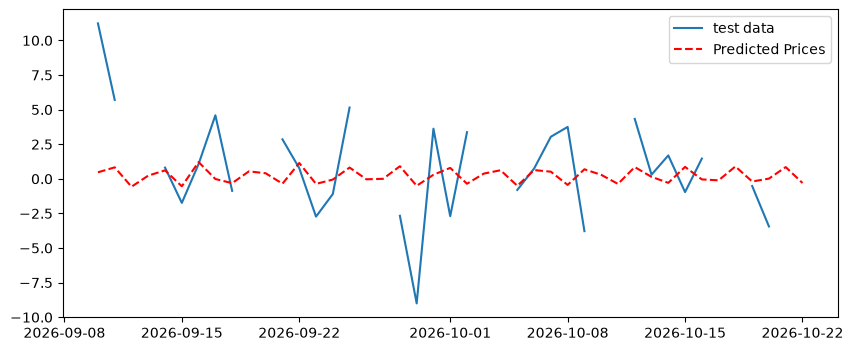

In [10]:
# fit the training data to the ARIMA model
model=ARIMA(train_data,order=(7,1,7))
model_fit=model.fit()

# make the predictions on the test data
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)

# plot the value v/s the predicted values
plt.figure(figsize=(10,4))
plt.plot(test_data.index,test_data,label="test data")
plt.plot(test_data.index,predictions,color="red",linestyle="--",label="Predicted Prices")


plt.legend()
plt.show()

# VECTOR models

In [12]:
tsla_data=yf.download("TSLA",start="2023-01-01")
stock_data["TSLA_Close"]=tsla_data["Close"]

stock_data["APPL_Close"]=stock_data["Close"].shift()
stock_data.dropna(inplace=True)

from statsmodels.tsa.stattools import grangercausalitytests

# performs
grangercausalitytests(stock_data[["APPL_Close","TSLA_Close"]].dropna(),maxlag=[14])
print()


[*********************100%***********************]  1 of 1 completed

In [17]:
tsla_data

Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2023-01-03,108.099998,118.800003,104.639999,118.470001,231402800
2023-01-04,113.639999,114.589996,107.519997,109.110001,180389000
2023-01-05,110.339996,111.750000,107.160004,110.510002,157986300
2023-01-06,113.059998,114.389999,101.809998,103.000000,220911100
2023-01-09,119.769997,123.519997,117.110001,118.959999,190284000
...,...,...,...,...,...
2026-10-15,362.440002,363.750000,355.230011,360.570007,26728300
2026-10-16,354.720001,370.500000,349.329987,369.149994,62067300


In [18]:
stock_data

Price,Close,High,Low,Open,Volume,TSLA_Close,APPL_Close
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,
Date,,,,,,,
2023-01-05,122.827614,125.529389,122.572179,124.900613,80962700,110.339996,124.144112
2023-01-06,127.346947,128.005196,122.699897,123.800259,87754700,113.059998,122.827614
2023-01-09,127.867645,131.070487,127.612210,128.182041,70790800,119.769997,127.346947
2023-01-10,128.437485,128.958189,125.873254,127.975726,63896200,118.849998,127.867645
2023-01-11,131.149078,131.168717,128.172215,128.948354,69458900,123.220001,128.437485
...,...,...,...,...,...,...,...
2026-10-15,342.000000,347.850006,341.600006,346.950012,39767300,362.440002,342.959991
2026-10-16,343.459991,347.820007,340.459991,346.089996,59946400,354.720001,342.000000


In [19]:
data=stock_data[["APPL_Close","TSLA_Close"]].diff().dropna()
train_data,test_data=data[:-14],data[-14:]

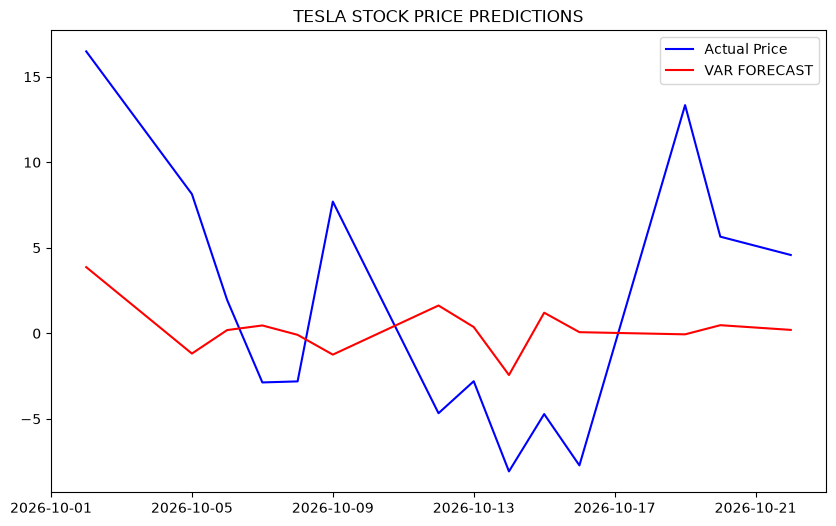

RMSE: 7.32


In [22]:
from statsmodels.tsa.api import VAR,VARMAX

# VAR
model=VAR(train_data)
result=model.fit(maxlags=12)
predictions=result.forecast(train_data.values[-result.k_ar:],steps=len(test_data))


predictions=pd.DataFrame(predictions,index=test_data.index,columns=test_data.columns)

plt.figure(figsize=(10,6))
plt.plot(test_data.index,test_data["TSLA_Close"],label="Actual Price",color="blue")
plt.plot(test_data.index,predictions["TSLA_Close"],label="VAR FORECAST",color="red")
plt.title("TESLA STOCK PRICE PREDICTIONS")
plt.legend()
plt.show()


# Evaluate the model
rmse=round(np.sqrt(mean_squared_error(test_data["TSLA_Close"],predictions["TSLA_Close"])),2)
print("RMSE:",rmse)

# VMA model

KeyError: 'TSLA_Close'

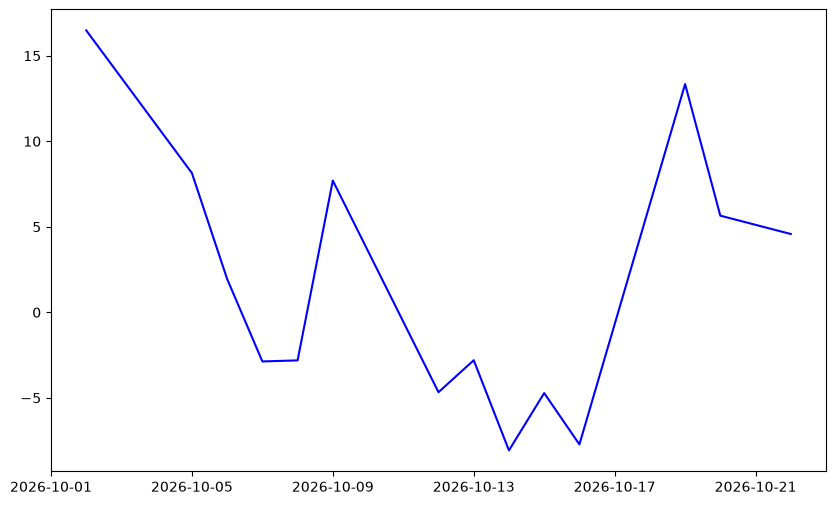

In [23]:
from statsmodels.tsa.api import VAR,VARMAX

# VAR
model=VARMAX(train_data,order=(0,14))
result=model.fit()
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)




plt.figure(figsize=(10,6))
plt.plot(test_data.index,test_data["TSLA_Close"],label="Actual Price",color="blue")
plt.plot(test_data.index,predictions["TSLA_Close"],label="VAR FORECAST",color="red")
plt.title("TESLA STOCK PRICE PREDICTIONS")
plt.legend()
plt.show()


# Evaluate the model
rmse=round(np.sqrt(mean_squared_error(test_data["TSLA_Close"],predictions["TSLA_Close"])),2)
print("RMSE:",rmse)

In [ ]:
from statsmodels.tsa.api import VAR,VARMAX

# VAR
model=VARMAX(train_data,order=(14,14))
result=model.fit()
predictions=model_fit.predict(
    start=len(train_data),
    end=len(train_data)+len(test_data)-1,
    dynamic=False)




plt.figure(figsize=(10,6))
plt.plot(test_data.index,test_data["TSLA_Close"],label="Actual Price",color="blue")
plt.plot(test_data.index,predictions["TSLA_Close"],label="VAR FORECAST",color="red")
plt.title("TESLA STOCK PRICE PREDICTIONS")
plt.legend()
plt.show()


# Evaluate the model
rmse=round(np.sqrt(mean_squared_error(test_data["TSLA_Close"],predictions["TSLA_Close"])),2)
print("RMSE:",rmse)